## Riconoscimento di anomalie dai dati di magnetomentro

In questo progetto ho deciso di provare a individuare i segnali di anomalie particolari, i fulmini, dai dati di un magnetometro, ovvero un misuratore di variazioni di campo magnetico.
Ho utilizzato i dati forniti da un magnetometro posizionato a L'Aquila con una lunga storia di misurazioni.

Invece come database di fulmini ho usato i dati di una rete internazionale, Blitzortung, che usa ricevitori VLF (very low frequencies) e incrocia i segnali da varie antenne con i timestamps degli eventi per trovarne la posizione tramite il calcolo del tempo di percorrenza delle onde.

Se già è presente una rete in grado di segnalare la scarica di un fulmine trovandone anche la posizione perché è necessario ripetere ricavare queste informazioni anche dai magnetometri?  La rete Blitzortung è relativamente giovane, è attiva dal 2005 ma ha iniziato a fornire risultati affidabili anni dopo, invece i magnetometri sono strumenti con una storia ben più lunga, quindi potrebbero essere utilizzati per ricavare una statistica negli anni dei fulmini. Inoltre il segnale dei fulmini sui magnetometri sono una fonte di rumore non trascurabile, quindi nell'ambito di altri tipi di misura sarebbe utile riconoscerne le caratteristiche per sottrarli al segnale principale.

Non è scontato inoltre che la rete Blitzortung funzioni perfettamente, quindi sarebbe utile verificarne i risultati.

In questo primo notebook non viene trattata affatto la rete neurale, ma c'è tutta la preparazione del dataset utilizzato per l'addestramento e test della rete. E' qui che vengono fatti la maggior parte dei ragionamenti fisici riguardo la misura fatta e la statistica dei fulmini.   Inoltre ho costruito un sistema di rilevamento dei fulmini puramente logico basato sul salto del segnale, in modo da avere un termine di paragone per accertarsi che le prestazioni della neural network siano sufficienti.

Nella cella 3b ci sono i plot di tre livelli di dettaglio per lo stesso giorno di temporale di dati di magnetometro in modo da vederne l'andamento.
1. **giornata intera**: le tre componenti (meno la mediana del giorno) e i fulmini del catalogo. La variazione lenta del campo vale qualche nT o decine di nT ed è dovuta all'attività geomagnetica e all'ora del giorno, non ai fulmini;
2. **zoom di ±5 minuti** attorno a un fulmine: in rosso la finestra di 9 s che viene data alla rete;
3. **la finestra di 9 s**, da −3 a +5 s rispetto al fulmine: in grigio l'intervallo 0…+3 s in cui la cella 4 mostra la risposta del magnetometro.

Il fulmine mostrato è quello con il salto più evidente del giorno, quindi è un caso favorevole: la maggior parte dei fulmini del catalogo produce segnali molto più piccoli, spesso confusi con il rumore.

# Lightning Detection Pipeline
Lettura dati magnetometro EMMA + catalogo fulmini → dataset per rete neurale.

Il dataset si costruisce e si salva su disco. Per ogni finestra vengono salvati anche:
- il salto massimo `max_deriv`;
- il rumore locale `noise_local` (mediana del salto nei 5 minuti precedenti) e quindi il rapporto segnale/rumore `snr`;
- la distanza `dt_lightning` dal fulmine di catalogo più vicino;
- se il giorno ha fulmini in catalogo (`day_has_lightning`).

**Categorie di finestre cella 7**

Ci sono 3 tipi di utilizzo per i dati: 
-train: per addestrare la rete neurale
-validation: per determinare i parametri e l'epoch più prestante
-test: per ottenere dati di diagnostica e statistiche di funzionamento della rete

| codice | categoria | uso |
|---|---|---|
| 1 | positiva **visibile** (fulmine in catalogo, salto ≥ soglia) | train / val / test |
| 3 | positiva **debole** (fulmine in catalogo, nessun segnale) | solo test, a titolo informativo |
| 0 | negativa **sicura**: lontana ≥ `SAFE_DISTANCE_H` ore da qualsiasi fulmine | train / val / test |
| 4 | negativa **quieta vicino ai temporali** (salto piccolo) | train / val / test |
| 2 | **ambigua**: vicino ai temporali, salto grande, nessun fulmine in catalogo | **mai nel train**, solo nel test |

Le negative sono di due tipi: le sicure sono lontane più di 24 ore da qualsiasi fulmine di catalogo, quindi sono affidabili anche se il segnale contiene salti forti, e da qui si prendono le negative "difficili" del train e il conteggio dei falsi allarmi; le quiete sono vicine ai temporali ma senza segnale visibile, quindi qualunque cosa sia accaduta non è rilevabile. Le quiete servono a mostrare alla rete finestre dei giorni di temporale senza fulmine, così che non impari a riconoscere il giorno di temporale invece del fulmine. Le finestre vicine ai temporali con segnale forte sono invece ambigue (possibili fulmini non in catalogo) e restano fuori dall'addestramento.

Flusso:
1. Configurazione
2. Lettura magnetometro (solo modalità single)
3. Lettura CSV fulmini
4. Diagnostica: il magnetometro vede i fulmini? (superposed epoch analysis)
5. Costruzione (o caricamento) del dataset completo
6. Esplorazione: positive vs negative, salti vs distanza dai temporali, distribuzione temporale del rumore
7. Selezione delle categorie e split train / validation / test
8. Salvataggio per la rete neurale

In [1]:
# Dipendenze standard
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from lightning_aligner import emma_to_series

# Moduli del progetto
from emma2013_reader import read_emma2013, print_header
from lightning_aligner import (
    load_lightning_csv,
    emma_to_series,
    check_lightning_signal,
    compute_deriv_threshold,
    compute_deriv_threshold_from_files,
    build_dataset,
    build_dataset_from_files,
    merge_datasets,
    save_dataset,
    load_dataset,
    save_training_dataset,
    load_training_dataset,
    superposed_epoch_analysis,
    LightningDataset,
)

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

## 1 · Configurazione

In [2]:
# Modalità
MODE = 'multi'          # 'single' oppure 'multi' per scegliere quanti files utilizzare.

# Percorsi
MAG_FILE  = Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\2025\D_AQU_2025_03_10_01Hz_v1.bin")  # file EMMA2013
MAG_FILES = sorted(Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\2025").glob("*.bin"))
print(f"File magnetometro trovati: {len(MAG_FILES)}")

LIGHTNING_FILE = Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\fulmini\AQU_2025_50km.dat")

# tenere None, per ampliamento futuro se si dovesse usare un catalogo di fulmini a più ampio raggio
LIGHTNING_FILE_WIDE = None

FULL_DATASET_FILE = Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\datasets\full_dataset_v3.npz")   # dataset completo, senza soglie
OUTPUT_FILE2      = Path(r"C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\datasets\lightning_dataset50km_v2.npz")  # dove salvare il dataset
# True  = ricostruisce il dataset dai 365 file (lento) e lo salva in FULL_DATASET_FILE
# False = ricarica FULL_DATASET_FILE (pochi secondi)
REBUILD = False

# Colonne del CSV fulmini
TIME_COL, LAT_COL, LON_COL = "Time", "Latitude", "Longitude"

# Parametri finestre
HALF_WINDOW     = 4     # ±4 s → 9 campioni
CENTER_OFFSET   = 1     # centro delle positive a +1 s dal fulmine → finestra [-3, +5] s
NAN_THRESHOLD   = 0.0   # nessun NaN ammesso nella finestra
NEGATIVE_STRIDE = 7     # passo (s) tra finestre negative
GUARD_SECONDS   = 3     # margine (s) tra i bordi di una negativa e il fulmine più vicino
NOISE_WINDOW    = 300   # secondi di quiete prima della finestra per stimare il rumore locale

NON_OVERLAP_POSITIVES = True # per non sovrapporre le finestre positive tra loro
OVERLAP_MODE          = "keep_first" ## "keep_first" = se due positive si sovrappongono, si tiene la prima e si scarta la seconda
DERIV_COMPONENTS      = (0, 1, 2)

# Le soglie NON si applicano in costruzione
DERIV_THRESHOLD     = None #Una finestra positiva con salto (derivata) sul magnetometro sotto questa soglia viene scartata come no signal
NEG_DERIV_THRESHOLD = None #Una finestra negativa con salto (derivata) sul magnetometro sopra questa soglia viene scartata come fulmine non in catalogo

print("Configurazione caricata.")

File magnetometro trovati: 365
Configurazione caricata.


## 2 · Lettura file magnetometro (singolo file)
Solo per `MODE = 'single'`.

In [ ]:
if MODE == 'single':
    header, raw_data, error = read_emma2013(MAG_FILE)
    if error.status:
        raise RuntimeError(f"Errore nella lettura del magnetometro: {error.message}")
    print_header(header)
    print(f"Campioni grezzi letti : {len(raw_data.time)}")

    # Converti in serie temporale pandas (nT, griglia regolare al secondo)
    mag_series = emma_to_series(header, raw_data)
    display(mag_series.head())

## 3 · Lettura CSV fulmini
Le righe con timestamp identico al millisecondo (stesso fulmine localizzato in più punti) vengono ridotte a una sola. Chiamata di funzione esterna.

In [3]:
lightning_df = load_lightning_csv(
    LIGHTNING_FILE,
    time_col = TIME_COL,
    lat_col  = LAT_COL,
    lon_col  = LON_COL,
)
print("\nPrimi eventi:")
lightning_df

[CSV fulmini] Rimossi 15711 eventi con timestamp duplicato
[CSV fulmini] Caricati 8859 eventi  (2025-01-26 12:46:11.991000 → 2025-11-28 14:44:18.713000)

Primi eventi:


,timestamp,latitude,longitude
0,2025-01-26 12:46:11.991,42.735599,13.024588
1,2025-01-28 09:52:17.508,42.583641,13.483980
2,2025-02-14 01:17:56.002,42.773543,13.132431
3,2025-02-14 04:26:58.733,41.985035,13.214354
4,2025-02-14 05:17:38.023,42.017084,13.658854
...,...,...,...
8854,2025-11-21 15:42:35.055,42.689506,13.654432
8855,2025-11-21 17:37:39.409,42.752752,13.629558
8856,2025-11-21 17:37:39.529,42.574611,13.703210
8857,2025-11-26 06:42:16.075,42.395946,12.782484


In [4]:
# Grafico delle tre componenti (solo modalità single)
if MODE == 'single':
    fig, axes = plt.subplots(3, 1, figsize=(14, 5), sharex=True)
    rf = header.reference_frame
    labels_comp = [rf[i] if len(rf) > i else f"comp{i+1}" for i in range(3)]

    for ax, col, lbl in zip(axes, ["comp1", "comp2", "comp3"], labels_comp):
        ax.plot(mag_series.index, mag_series[col], lw=0.6, color="steelblue")
        ax.set_ylabel(lbl, fontsize=9)
        ax.grid(True, alpha=0.3)

    lightning_day = lightning_df[lightning_df["timestamp"].dt.date == mag_series.index[0].date()]
    for ax in axes:
        for t in lightning_day["timestamp"]:
            ax.axvline(t, color="red", linestyle="--", linewidth=0.8, alpha=0.7)
    axes[-1].set_xlabel("Tempo (UTC)")
    fig.suptitle(f"Magnetometro {header.name} [{header.iaga_code}] — "
                 f"{header.year:04d}-{header.month:02d}-{header.day:02d}", fontsize=10)
    fig.tight_layout()
    plt.show()

[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)


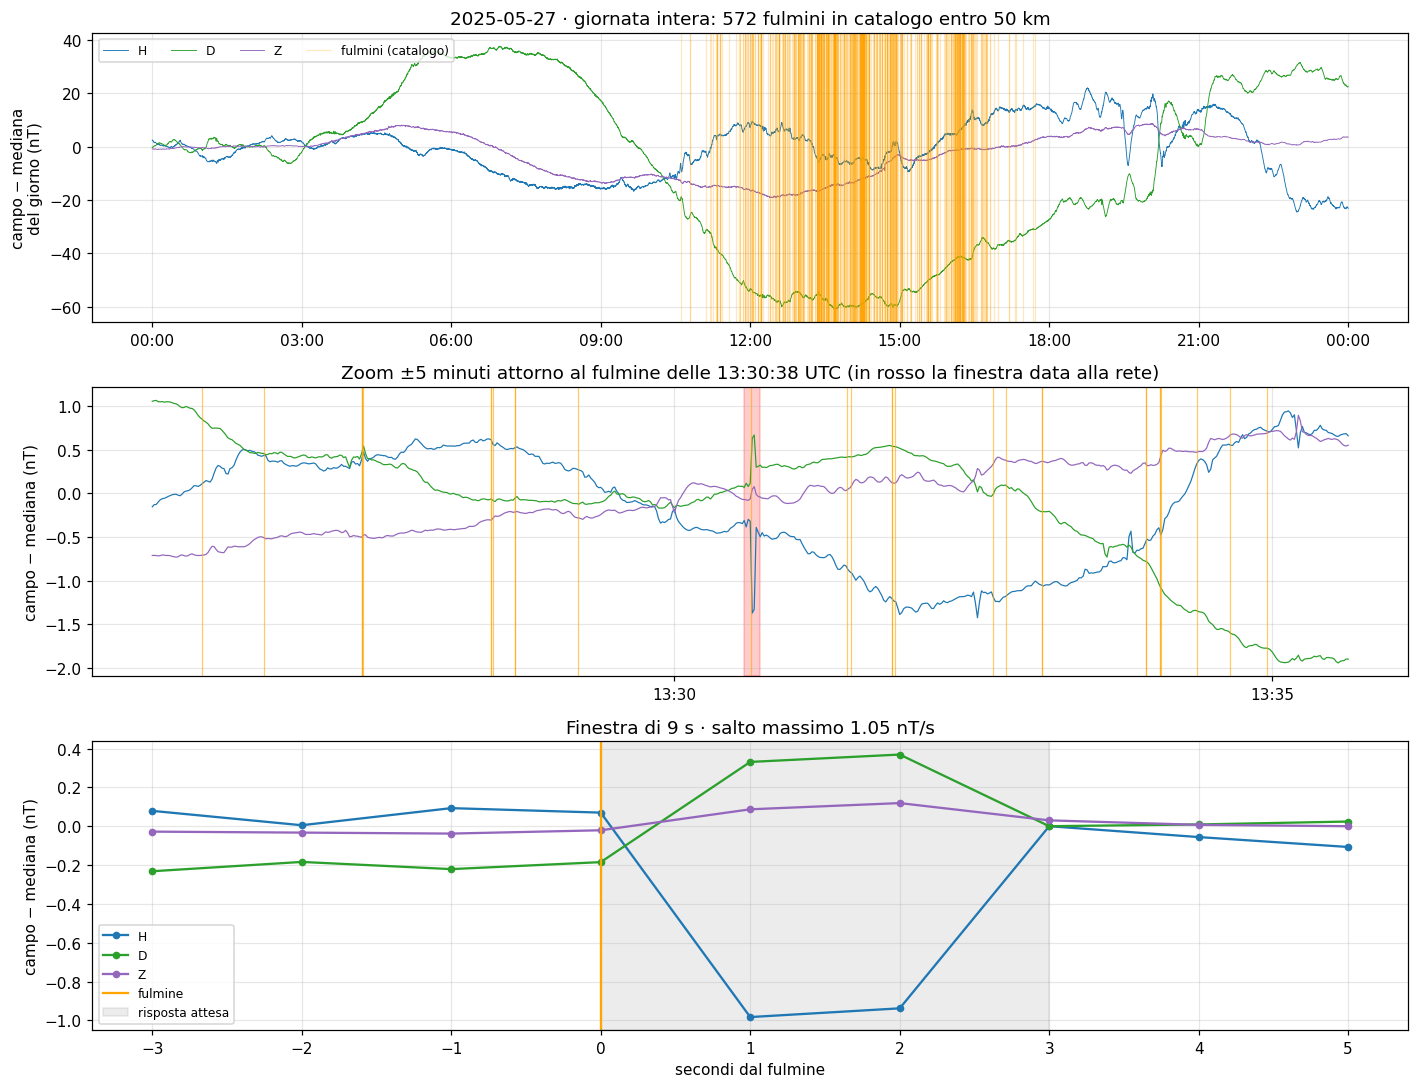

In [7]:
# Esempi di dati del magnetometro

GIORNO_ESEMPIO = None      # es. "2025-06-15"; None = giorno con più fulmini in catalogo

# file disponibili per giorno (nome: D_AQU_AAAA_MM_GG_01Hz_v1.bin)
file_per_giorno = {pd.Timestamp("-".join(f.stem.split("_")[2:5])): f for f in MAG_FILES}

if GIORNO_ESEMPIO is None:
    conteggi = lightning_df["timestamp"].dt.normalize().value_counts()
    giorno = next(g for g in conteggi.index if g in file_per_giorno)
else:
    giorno = pd.Timestamp(GIORNO_ESEMPIO)

header_e, raw_e, err = read_emma2013(file_per_giorno[giorno])
if err.status:
    raise RuntimeError(err.message)
mag_e = emma_to_series(header_e, raw_e)
lt_e  = lightning_df.loc[lightning_df["timestamp"].dt.normalize() == giorno, "timestamp"]

cols   = ["comp1", "comp2", "comp3"]
rf     = header_e.reference_frame
nomi   = [rf[i] if len(rf) > i else f"comp{i+1}" for i in range(3)]
colori = ["tab:blue", "tab:green", "tab:purple"]
x      = mag_e[cols]

# fulmine con il salto più evidente tra 0 e +3 s
d = x.diff().abs().max(axis=1)
def salto(t):
    t0 = t.floor("s")
    return d.loc[t0: t0 + pd.Timedelta(seconds=3)].max()
salti = lt_e.apply(salto).fillna(-1)
t_lt  = lt_e.loc[salti.idxmax()].floor("s")
w_ini = t_lt + pd.Timedelta(seconds=CENTER_OFFSET - HALF_WINDOW)
w_fin = t_lt + pd.Timedelta(seconds=CENTER_OFFSET + HALF_WINDOW)

fig, axes = plt.subplots(3, 1, figsize=(13, 10))

# 1) giornata intera
ax = axes[0]
for c, n, col in zip(cols, nomi, colori):
    ax.plot(x.index, x[c] - x[c].median(), lw=0.6, color=col, label=n)
y0, y1 = ax.get_ylim()
ax.vlines(lt_e, y0, y1, color="orange", alpha=0.25, lw=0.8, label="fulmini (catalogo)")
ax.set_ylim(y0, y1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylabel("campo − mediana\ndel giorno (nT)")
ax.set_title(f"{giorno.date()} · giornata intera: {len(lt_e)} fulmini in catalogo entro 50 km")
ax.legend(loc="upper left", fontsize=8, ncol=4); ax.grid(alpha=0.3)

# 2) zoom ±5 minuti
ax = axes[1]
seg = x.loc[t_lt - pd.Timedelta(minutes=5): t_lt + pd.Timedelta(minutes=5)]
for c, n, col in zip(cols, nomi, colori):
    ax.plot(seg.index, seg[c] - seg[c].median(), lw=0.8, color=col, label=n)
lt_seg = lt_e[(lt_e >= seg.index[0]) & (lt_e <= seg.index[-1])]
y0, y1 = ax.get_ylim()
ax.vlines(lt_seg, y0, y1, color="orange", alpha=0.6, lw=0.8)
ax.set_ylim(y0, y1)
ax.axvspan(w_ini, w_fin, color="red", alpha=0.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylabel("campo − mediana (nT)")
ax.set_title(f"Zoom ±5 minuti attorno al fulmine delle {t_lt.time()} UTC (in rosso la finestra data alla rete)")
ax.grid(alpha=0.3)

# 3) la finestra di 9 s
ax = axes[2]
w   = x.loc[w_ini: w_fin]
sec = (w.index - t_lt).total_seconds()
for c, n, col in zip(cols, nomi, colori):
    ax.plot(sec, w[c] - w[c].median(), "o-", ms=4, color=col, label=n)
ax.axvline(0, color="orange", lw=1.5, label="fulmine")
ax.axvspan(0, 3, color="gray", alpha=0.15, label="risposta attesa")
ax.set_xlabel("secondi dal fulmine"); ax.set_ylabel("campo − mediana (nT)")
ax.set_title(f"Finestra di {2*HALF_WINDOW + 1} s · salto massimo {salti.max():.2f} nT/s")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

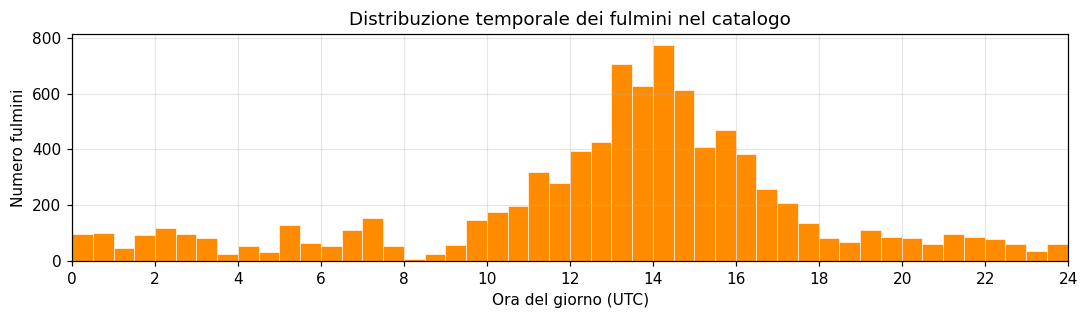

In [8]:
# Distribuzione oraria dei fulmini
fig, ax = plt.subplots(figsize=(10, 3))
hours = lightning_df["timestamp"].dt.hour + lightning_df["timestamp"].dt.minute / 60
ax.hist(hours, bins=48, color="darkorange", edgecolor="white", linewidth=0.4)
ax.set_xlabel("Ora del giorno (UTC)")
ax.set_ylabel("Numero fulmini")
ax.set_title("Distribuzione temporale dei fulmini nel catalogo")
ax.set_xlim(0, 24)
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4 · Diagnostica: il magnetometro vede i fulmini? Gli orologi sono allineati?
Fa la media di |Δ| attorno a **tutti** i fulmini del catalogo, in funzione del ritardo dal fulmine.

- **picco netto a ritardo 0** → il segnale c'è, si può procedere;
- **picco a ±3600 s o ±7200 s** → il CSV è in ora italiana e non in UTC;
- **picco a ±1–2 s** → ritardo strumentale da correggere;
- **nessun picco** (rapporto picco/fondo ≈ 1) → a 1 Hz il magnetometro non vede i fulmini: nessuna rete potrà impararli.

File con fulmini: 103
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 138 (0.2%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 618 (0.7%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 756 (0.9%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 138 (0.2%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetometro] 86400 campioni  |  NaN: 0 (0.0%)
[Magnetome

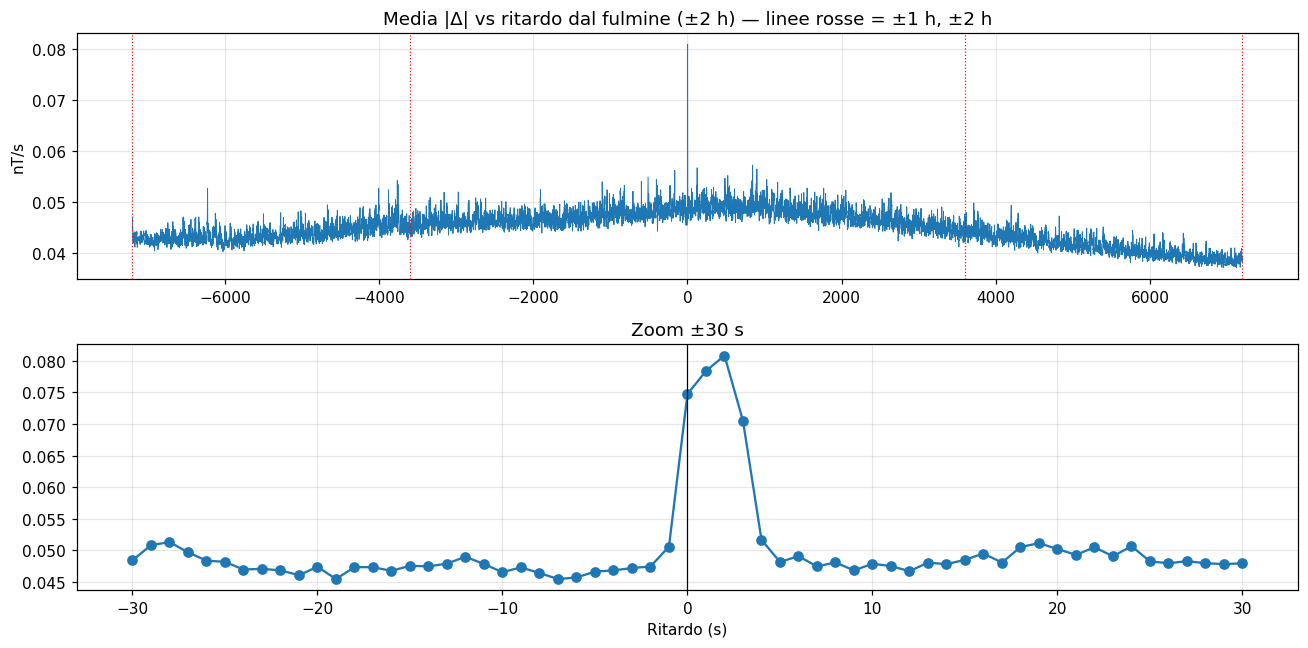

Livello di fondo     : 0.0450 nT/s
Valori a lag -1..+1  : [0.05058691 0.07473487 0.07836535]
Rapporto picco/fondo : 1.80  (il magnetometro non vede i fulmini a lag 0)


In [9]:
giorni_con_fulmini = set(lightning_df["timestamp"].dt.strftime("%Y_%m_%d"))
files_sea = [f for f in MAG_FILES if any(g in f.name for g in giorni_con_fulmini)]
print(f"File con fulmini: {len(files_sea)}")

lags, mean_d, cnt = superposed_epoch_analysis(files_sea, lightning_df, max_lag_s=7200)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(lags, mean_d, lw=0.6)
for h in (-7200, -3600, 3600, 7200):
    axes[0].axvline(h, color="red", ls=":", lw=0.8)
axes[0].set_title("Media |Δ| vs ritardo dal fulmine (±2 h) — linee rosse = ±1 h, ±2 h")
axes[0].set_ylabel("nT/s")
z = np.abs(lags) <= 30
axes[1].plot(lags[z], mean_d[z], "o-")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("Zoom ±30 s")
axes[1].set_xlabel("Ritardo (s)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fondo = np.nanmedian(mean_d[np.abs(lags) > 60])
print(f"Livello di fondo     : {fondo:.4f} nT/s")
print(f"Valori a lag -1..+1  : {mean_d[np.abs(lags) <= 1]}")
print(f"Rapporto picco/fondo : {np.nanmax(mean_d[np.abs(lags) <= 2]) / fondo:.2f}  "
      f"(il magnetometro non vede i fulmini a lag 0)")

Ovvero i fulmini, in media sono in ritardo di circa un secondo e per questo le finestre sono shiftate nella cella di configurazione. Ciò è dovuto principalmente dal fatto che i dati sono a 1Hz.

## 5 · Costruzione (o caricamento) del dataset completo
Con `REBUILD = True` legge tutti i file (lento) e salva il risultato in `FULL_DATASET_FILE`. Le volte successive con `REBUILD = False` il dataset si ricarica in pochi secondi e si possono rieseguire le celle 6–8 con soglie diverse.

In [10]:
if REBUILD:
    dist_df = None
    if LIGHTNING_FILE_WIDE is not None:
        dist_df = load_lightning_csv(LIGHTNING_FILE_WIDE, time_col=TIME_COL,
                                     lat_col=LAT_COL, lon_col=LON_COL)
    common = dict(
        half_window      = HALF_WINDOW,
        nan_threshold    = NAN_THRESHOLD,
        negative_stride  = NEGATIVE_STRIDE,
        guard_seconds    = GUARD_SECONDS,
        deriv_threshold  = DERIV_THRESHOLD,
        deriv_components = DERIV_COMPONENTS,
        neg_deriv_threshold   = NEG_DERIV_THRESHOLD,
        non_overlap_positives = NON_OVERLAP_POSITIVES,
        overlap_mode          = OVERLAP_MODE,
        center_offset         = CENTER_OFFSET,
        noise_window          = NOISE_WINDOW,
    )
    if MODE == 'single':
        ref = (dist_df if dist_df is not None else lightning_df)
        dataset = build_dataset(
            header=header, raw_data=raw_data, lightning_df=lightning_df,
            dist_lightning_times=np.sort(ref["timestamp"].dt.round("s").values.astype("datetime64[s]")),
            **common)
    else:
        dataset = build_dataset_from_files(
            mag_files=MAG_FILES, lightning_df=lightning_df, skip_errors=True,
            dist_lightning_df=dist_df, keep_meta=False, **common)
    FULL_DATASET_FILE.parent.mkdir(parents=True, exist_ok=True)
    save_dataset(dataset, FULL_DATASET_FILE)
else:
    dataset = load_dataset(FULL_DATASET_FILE)
    print(f"Dataset caricato da {FULL_DATASET_FILE}")

dataset.summary()

Dataset caricato da C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\datasets\full_dataset_v3.npz
─────────────────────────────────────────────
  Finestre totali    : 4501303
  Finestre valide    : 4386755
    di cui positive  : 5691  (con fulmine)
    di cui negative  : 4381064  (senza fulmine)
  Finestre scartate  : 114548
    con troppi NaN                                  : 111486
    positive sovrapposte                            : 3062
─────────────────────────────────────────────


## 6 · Esplorazione

In [11]:
# Solo finestre valide (niente NaN / sovrapposizioni)
ok      = dataset.valid_mask
is_pos  = ok &  dataset.has_lightning
is_neg  = ok & ~dataset.has_lightning
md      = dataset.max_deriv
snr     = dataset.snr
dt_abs  = np.abs(dataset.dt_lightning)
t_all   = pd.DatetimeIndex(dataset.t_center)
print(f"Positive valide: {is_pos.sum():,}   Negative valide: {is_neg.sum():,}")
print(f"Rumore locale mediano: {np.nanmedian(dataset.noise_local[is_neg]):.4f} nT/s")

Positive valide: 5,691   Negative valide: 4,381,064
Rumore locale mediano: 0.0160 nT/s


### 6a · Positive vs negative: salto massimo e rapporto segnale/rumore
A sinistra il salto assoluto, a destra lo stesso salto diviso per il rumore dei 5 minuti precedenti. Se a destra le due distribuzioni sono più separate, conviene usare `CRITERIO = "snr"` (signal to noise ratio) nella cella 7.

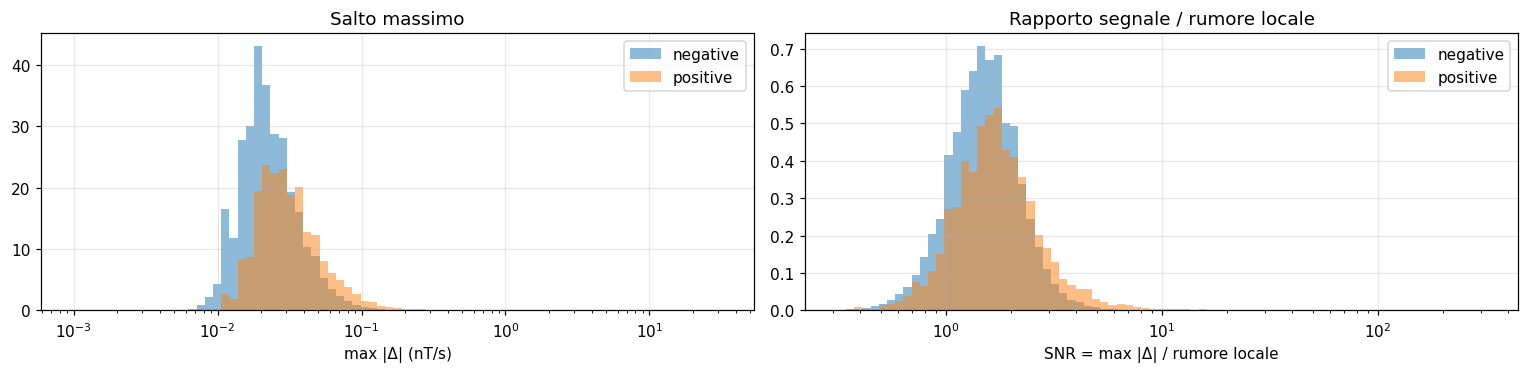

 percentile positive | max_deriv % neg sopra |    snr % neg sopra
                 p50 |     0.040      25.59% |   2.06      30.33%
                 p75 |     0.066       7.91% |   3.00       7.77%
                 p90 |     0.119       1.60% |   5.06       0.95%
                 p95 |     0.202       0.38% |   8.80       0.12%
                 p99 |     0.674       0.02% |  34.81       0.01%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, val, nome, bins in [
    (axes[0], md,  "max |Δ| (nT/s)",          np.logspace(-3, 1.5, 80)),
    (axes[1], snr, "SNR = max |Δ| / rumore locale", np.logspace(-0.5, 2.5, 80)),
]:
    vn, vp = val[is_neg], val[is_pos]
    ax.hist(vn[np.isfinite(vn)], bins=bins, density=True, alpha=0.5, label="negative")
    ax.hist(vp[np.isfinite(vp)], bins=bins, density=True, alpha=0.5, label="positive")
    ax.set_xscale("log"); ax.set_xlabel(nome); ax.grid(alpha=0.3); ax.legend()
axes[0].set_title("Salto massimo")
axes[1].set_title("Rapporto segnale / rumore locale")
plt.tight_layout(); plt.show()

print(f"{'percentile positive':>20s} | {'max_deriv':>9s} {'% neg sopra':>11s} | {'snr':>6s} {'% neg sopra':>11s}")
for p in [50, 75, 90, 95, 99]:
    a = np.nanpercentile(md[is_pos], p);  fa = np.mean(md[is_neg] >= a) * 100
    b = np.nanpercentile(snr[is_pos], p); fb = np.nanmean(snr[is_neg] >= b) * 100
    print(f"{'p'+str(p):>20s} | {a:9.3f} {fa:10.2f}% | {b:6.2f} {fb:10.2f}%")

Due distribuzioni sono più separate quando si sovrappongono meno: sopra una certa soglia finiscono molte positive e poche negative. Con il criterio migliore, a parità di positive tenute, le negative che superano la soglia (i futuri falsi allarmi) sono meno. La tabella confronta le code: a parità di positive selezionate, conta quante negative superano la soglia nel caso di massima derivata e di snr. Nella parte centrale i due criteri si equivalgono, perché le positive sono quasi tutte indistinguibili dal rumore. Nella coda (p90 e oltre), dove si trovano i fulmini con segnale visibile, l'SNR riduce le negative sopra soglia di 2–3 volte (per esempio 0.95% contro 1.60% al p90). Per questo nella cella 7 si usa CRITERIO = "snr".

### 6b · I salti forti "senza fulmine" si concentrano attorno ai temporali?
Per ogni negativa si guarda quanto dista dal fulmine di catalogo più vicino, e si calcola la frazione di finestre con salto sopra varie soglie.

- Se la frazione cresce avvicinandosi ai fulmini, molti salti "di rumore" sono legati ai temporali → probabilmente fulmini non in catalogo che si ferma a 50km e che comunque ha una affidabilità non verificata.
- Se la curva è piatta, quei salti sono rumore indipendente dai temporali.

L'ultimo punto ("giorni senza fulmini") è il riferimento: è il livello di rumore "puro".

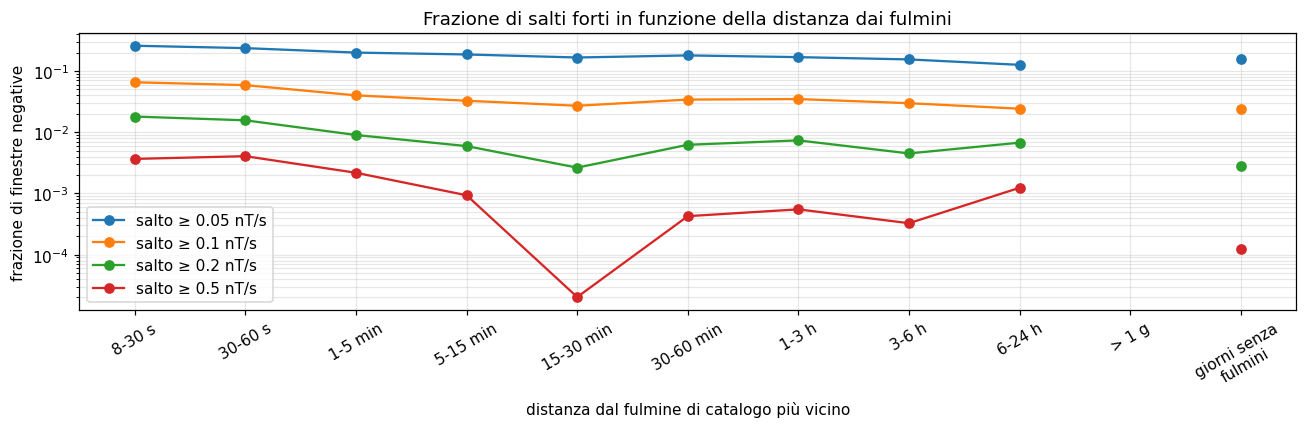

Finestre per intervallo: [25363, 21661, 62035, 54580, 49224, 72802, 227217, 284780, 441907, 0] | giorni senza fulmini: 3141495


In [13]:
edges = np.array([8, 30, 60, 300, 900, 1800, 3600, 3*3600, 6*3600, 24*3600, np.inf])
labels_b = ["8-30 s", "30-60 s", "1-5 min", "5-15 min", "15-30 min", "30-60 min",
            "1-3 h", "3-6 h", "6-24 h", "> 1 g"]
neg_storm = is_neg & dataset.day_has_lightning
neg_free  = is_neg & ~dataset.day_has_lightning
b_idx = np.digitize(dt_abs, edges) - 1

soglie_6b = [0.05, 0.1, 0.2, 0.5]
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(labels_b) + 1)
for s in soglie_6b:
    y = [np.mean(md[neg_storm & (b_idx == k)] >= s) if (neg_storm & (b_idx == k)).any() else np.nan
         for k in range(len(labels_b))]
    y.append(np.mean(md[neg_free] >= s) if neg_free.any() else np.nan)
    ax.plot(x, y, "o-", label=f"salto ≥ {s} nT/s")
ax.set_xticks(x, labels_b + ["giorni senza\nfulmini"], rotation=30)
ax.set_yscale("log"); ax.set_ylabel("frazione di finestre negative")
ax.set_xlabel("distanza dal fulmine di catalogo più vicino")
ax.set_title("Frazione di salti forti in funzione della distanza dai fulmini")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

print("Finestre per intervallo:", [int((neg_storm & (b_idx == k)).sum()) for k in range(len(labels_b))],
      "| giorni senza fulmini:", int(neg_free.sum()))

Le percentuali di seguito indicano quante delle finestre negative hanno un salto registrato maggiore di una soglia prefissata.

In [14]:
for s in soglie_6b:
    vicino = neg_storm & (dt_abs < 60)
    f_v, f_l = np.mean(md[vicino] >= s), np.mean(md[neg_free] >= s)
    print(f"salto ≥ {s}: entro 1 min = {f_v:.4%}   giorni senza fulmini = {f_l:.4%}   rapporto = {f_v/f_l:.1f}×")

salto ≥ 0.05: entro 1 min = 24.8299%   giorni senza fulmini = 15.7140%   rapporto = 1.6×
salto ≥ 0.1: entro 1 min = 6.2394%   giorni senza fulmini = 2.3862%   rapporto = 2.6×
salto ≥ 0.2: entro 1 min = 1.6928%   giorni senza fulmini = 0.2856%   rapporto = 5.9×
salto ≥ 0.5: entro 1 min = 0.3849%   giorni senza fulmini = 0.0124%   rapporto = 31.1×


Il punto a 15–30 minuti della curva ≥ 0.5 nT/s corrisponde a una sola finestra su 49 224 ed è anomalo rispetto agli intervalli vicini (decine di finestre). La classe ≥ 0.5 nT/s è dominata da una sorgente di disturbo concentrata alle 6–7 UTC (vedi 6c), quindi è sensibile alla distribuzione oraria delle finestre in ciascun intervallo. Le conclusioni si basano sull'andamento complessivo delle curve, non su questo punto. Il punto finale che sembra rialzarsi ha una spiegazione nella prossima cella.

### 6c · Distribuzione temporale del rumore, per intensità, confrontata con i fulmini
La figura mostra quando si verificano i salti nelle finestre negative, divisi in quattro classi di intensità (righe 1–4), per mese (sinistra) e per ora UTC (destra), confrontati con la distribuzione dei fulmini del catalogo (riga 5). I valori sono normalizzati come "finestre per ora di dati" per compensare i periodi senza dati.

Se una classe di rumore ha lo stesso andamento dei fulmini (stessi mesi, stesse ore), è un indizio che quei salti siano legati ai temporali. Se invece segue, per esempio, le ore lavorative o il giorno, l'origine è probabilmente umana o geomagnetica.

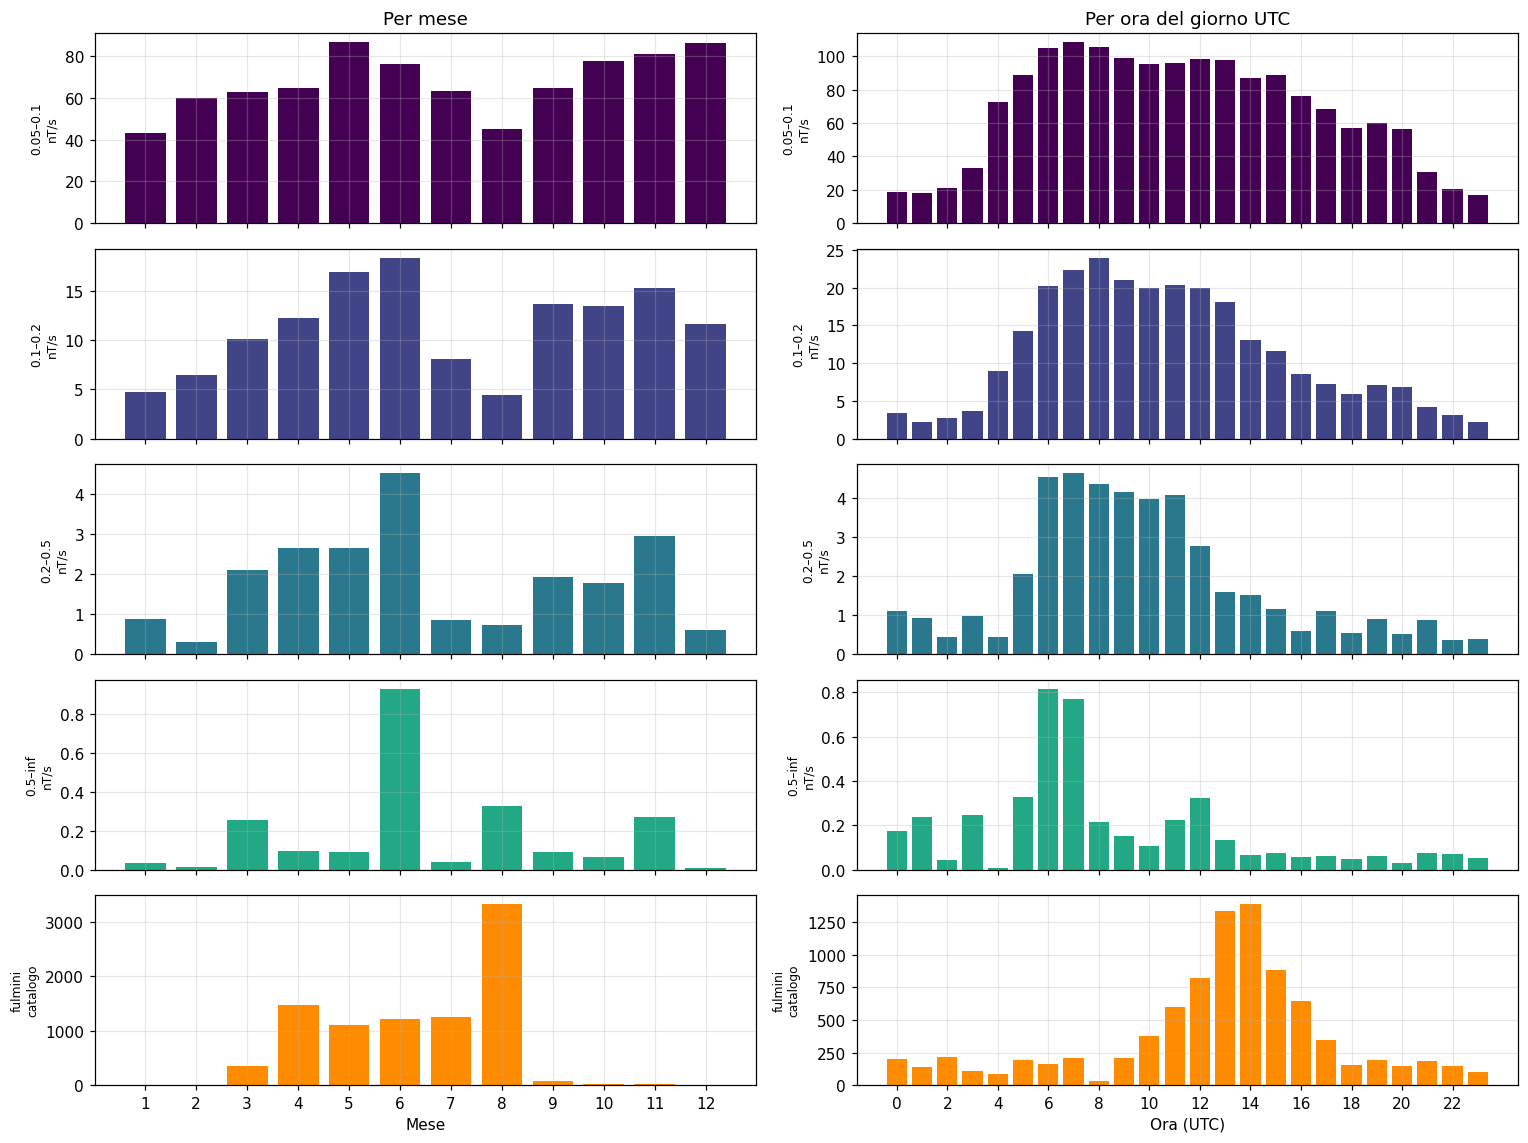

In [15]:
CLASSI_RUMORE = [(0.05, 0.1), (0.1, 0.2), (0.2, 0.5), (0.5, np.inf)]   # nT/s
per_ora = 3600 / NEGATIVE_STRIDE      # finestre negative in un'ora di dati

tn = t_all[is_neg]
dfn = pd.DataFrame({"month": tn.month, "hour": tn.hour, "day": tn.normalize(), "md": md[is_neg]})
lt = lightning_df["timestamp"]
lt = lt[(lt >= t_all.min()) & (lt <= t_all.max())]

nrow = len(CLASSI_RUMORE) + 1
fig, axes = plt.subplots(nrow, 2, figsize=(14, 2.1 * nrow), sharex="col")
for j, key in enumerate(["month", "hour"]):
    tot = dfn.groupby(key).size()
    for i, (lo, hi) in enumerate(CLASSI_RUMORE):
        cnt = dfn[(dfn.md >= lo) & (dfn.md < hi)].groupby(key).size().reindex(tot.index, fill_value=0)
        rate = cnt / tot * per_ora
        axes[i, j].bar(rate.index, rate.values, color=plt.cm.viridis(i / nrow), width=0.8)
        axes[i, j].set_ylabel(f"{lo}–{hi}\nnT/s", fontsize=8)
        axes[i, j].grid(alpha=0.3)
    cnt_lt = (lt.dt.month if key == "month" else lt.dt.hour).value_counts().sort_index()
    axes[-1, j].bar(cnt_lt.index, cnt_lt.values, color="darkorange", width=0.8)
    axes[-1, j].set_ylabel("fulmini\ncatalogo", fontsize=8)
    axes[-1, j].grid(alpha=0.3)
axes[0, 0].set_title("Per mese")
axes[0, 1].set_title("Per ora del giorno UTC")
axes[-1, 0].set_xlabel("Mese"); axes[-1, 0].set_xticks(range(1, 13))
axes[-1, 1].set_xlabel("Ora (UTC)"); axes[-1, 1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

In [16]:
vicino  = neg_storm & (dt_abs < 60)                                # entro 1 min dal fulmine
lontano = neg_storm & (dt_abs >= 3*3600) & (dt_abs < 6*3600)       # stessi giorni, 3–6 h dal fulmine

print(f"finestre: entro 1 min = {vicino.sum()}, 3–6 h = {lontano.sum()}")
for s in soglie_6b:
    n_v, n_l = (md[vicino] >= s).sum(), (md[lontano] >= s).sum()
    f_v, f_l = n_v / vicino.sum(), n_l / lontano.sum()
    print(f"salto ≥ {s}: entro 1 min = {f_v:.4%} ({n_v})   3–6 h = {f_l:.4%} ({n_l})   rapporto = {f_v/f_l:.1f}×")

finestre: entro 1 min = 47024, 3–6 h = 284780
salto ≥ 0.05: entro 1 min = 24.8299% (11676)   3–6 h = 15.4547% (44012)   rapporto = 1.6×
salto ≥ 0.1: entro 1 min = 6.2394% (2934)   3–6 h = 2.9788% (8483)   rapporto = 2.1×
salto ≥ 0.2: entro 1 min = 1.6928% (796)   3–6 h = 0.4505% (1283)   rapporto = 3.8×
salto ≥ 0.5: entro 1 min = 0.3849% (181)   3–6 h = 0.0327% (93)   rapporto = 11.8×


Il rumore delle classi fino a 0.5 nT/s segue un ciclo diurno (massimo tra le 5 e le 13 UTC), diverso da quello dei fulmini (massimo tra le 12 e le 15 UTC). Ad agosto, mese con più fulmini, il rumore è tra i più bassi dell'anno. La correlazione (calcolata dopo) giornaliera tra rumore e numero di fulmini è nulla per le classi deboli e moderata solo per la classe oltre 0.5 nT/s (rho = 0.33). La maggior parte del rumore ha quindi un'origine indipendente dai temporali, probabilmente antropica o legata alle variazioni diurne del campo geomagnetico. La classe oltre 0.5 nT/s presenta inoltre un picco anomalo alle 6–7 UTC, concentrato a giugno, attribuibile a una sorgente di disturbo specifica.

Il rialzo della curva ≥ 0.5 nT/s nell'intervallo 6–24 h (grafico 6b) non dipende dai fulmini: la 6c mostra che i salti più intensi sono concentrati alle 6–7 UTC, soprattutto a giugno. Nei giorni di temporale queste ore precedono di 6–8 ore i fulmini pomeridiani e cadono quindi in quell'intervallo. Per lo stesso motivo il confronto con i giorni senza fulmini, prevalentemente invernali e autunnali, include una differenza stagionale. Usando come riferimento le finestre degli stessi giorni di temporale lontane dai fulmini (3–6 h), l'eccesso di salti forti entro 1 minuto dai fulmini resta di circa un ordine di grandezza.
Più dettagliatamente il confronto con i giorni senza fulmini mescola due effetti: la vicinanza ai fulmini e la stagione, perché i giorni senza fulmini sono soprattutto invernali e il rumore cambia con la stagione. Per isolare l'effetto dei fulmini si possono usare come riferimento le finestre degli stessi giorni di temporale, ma lontane 3–6 ore dai fulmini: anche così, entro 1 minuto dai fulmini i salti ≥ 0.5 nT/s sono circa 10 volte più frequenti. L'incertezza su quest'ultimo dato è bassa perché il numero di finestre tra parentesi è grande.
Quest'ultima analisi elimina la differenza stagionale (la più importante) e non quella oraria, ma dato che il rapporto tra i salti entro 1 minuto dai fulmini e tra i salti a 3-6h è elevato, la conclusione, ovvero che i salti intensi (fulmini oltre i 50km) sono nei pressi dei temporali, rimane solida.

L'assenza di correlazione tra rumore e temporali nella 6c non contraddice la 6b. Le finestre entro pochi minuti da un fulmine sono circa il 2–3% del totale, quindi il loro contributo si diluisce nei conteggi orari, mensili e giornalieri, dominati dal rumore diurno. Solo per la classe più intensa (oltre 0.5 nT/s), di cui circa un quarto cade a ridosso dei fulmini, emerge una correlazione giornaliera moderata (rho = 0.33).

La 6c non mostra un legame forte tra rumore e temporali perché somma tutte le finestre di ore, mesi o giorni interi. I minuti vicini ai fulmini sono solo il 2–3% del tempo totale, quindi il loro contributo si perde nei totali. Il legame si vede solo per i salti più forti (oltre 0.5 nT/s): circa un quarto di essi cade vicino a un fulmine, e la correlazione di Spearman tra il loro numero giornaliero e il numero di fulmini del giorno è moderata (rho = 0.33). Per le classi più deboli è nulla. Il coefficiente di Spearman confronta l'ordinamento dei giorni secondo le due grandezze: vale +1 se coincidono, 0 se non c'è relazione.

#### Andamento giorno per giorno nell'anno
Ogni curva è il tasso giornaliero di una classe di rumore; le barre arancioni sono i fulmini del catalogo nello stesso giorno. Sotto, la correlazione (Spearman) tra il tasso di rumore giornaliero e il numero di fulmini: vicino a 0 = nessuna relazione, vicino a 1 = il rumore aumenta nei giorni di temporale.

Correlazione (Spearman) tasso giornaliero di rumore ↔ fulmini del giorno
   classe  0.05–0.1   nT/s : rho = -0.07
   classe   0.1–0.2   nT/s : rho = +0.02
   classe   0.2–0.5   nT/s : rho = +0.17
   classe   0.5–inf   nT/s : rho = +0.33


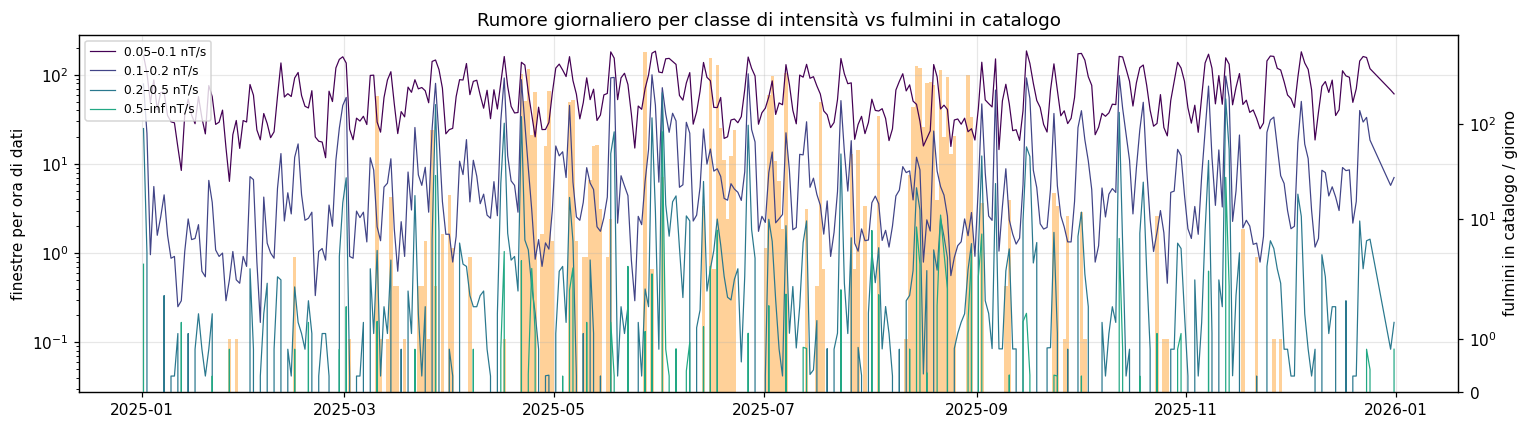

In [17]:
tot_d = dfn.groupby("day").size()
tot_d = tot_d[tot_d > 0.2 * 86400 / NEGATIVE_STRIDE]          # giorni con almeno il 20% di dati
lt_d = lt.dt.normalize().value_counts().reindex(tot_d.index, fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax2 = ax.twinx()
ax2.bar(lt_d.index, lt_d.values, color="darkorange", alpha=0.4, width=1.0, align="edge", label="fulmini/giorno")
ax2.set_yscale("symlog"); ax2.set_ylabel("fulmini in catalogo / giorno")
print("Correlazione (Spearman) tasso giornaliero di rumore ↔ fulmini del giorno")
for i, (lo, hi) in enumerate(CLASSI_RUMORE):
    cnt = dfn[(dfn.md >= lo) & (dfn.md < hi)].groupby("day").size().reindex(tot_d.index, fill_value=0)
    rate = cnt / tot_d * per_ora
    ax.plot(rate.index + pd.Timedelta(hours=12), rate.values, lw=0.8, color=plt.cm.viridis(i / nrow), label=f"{lo}–{hi} nT/s")
    rho = pd.Series(rate.values).corr(pd.Series(lt_d.values), method="spearman")
    print(f"   classe {lo:>5}–{hi:<5} nT/s : rho = {rho:+.2f}")
ax.set_yscale("log"); ax.set_ylabel("finestre per ora di dati")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
ax.set_title("Rumore giornaliero per classe di intensità vs fulmini in catalogo")
plt.tight_layout(); plt.show()

## 7 · Selezione delle categorie e split train / validation / test
Questa è la cella da modificare per provare soglie diverse

- `CRITERIO`: `"max_deriv"` (salto in nT/s) oppure `"snr"` (salto / rumore locale). Scegli in base al grafico 6a.
- `SOGLIA_POS`: sopra questa soglia una positiva è "visibile". Usa il grafico 6a: dove le negative diventano rare.
- `SOGLIA_AMBIGUA`: vicino ai temporali, una negativa sopra questa soglia è "ambigua" (forse un fulmine non in catalogo) e non entra nel train.
- `SAFE_DISTANCE_H`: oltre questa distanza dal fulmine più vicino, una negativa è "sicura". Dal grafico 6b: dove le curve diventano piatte.
- `HARD_NEG_FRACTION`: frazione delle negative del train, scelte tra quelle sicure con salto forte (le più difficili). Costringono la rete a imparare la forma del segnale.

In [18]:
CRITERIO          = "snr"   # oppure "snr" o max_deriv
SOGLIA_POS        = 5.0          # nT/s se max_deriv, adimensionale se snr
SOGLIA_AMBIGUA    = 3.0          # di solito ~ metà di SOGLIA_POS
SAFE_DISTANCE_H   = 24           # ore
HARD_NEG_FRACTION = 0.5
NEG_RATIO         = 3             # negative per positiva nel train
TRAIN_FRACTION    = 0.70          # frazione (in ordine di tempo) delle positive visibili
VAL_FRACTION      = 0.10          # il resto è test
SEED              = 42

score = md if CRITERIO == "max_deriv" else snr
finite = np.isfinite(score)
safe  = dt_abs >= SAFE_DISTANCE_H * 3600

cat = np.full(dataset.n_samples, -1, dtype=np.int8)           # -1 = esclusa
cat[is_pos & finite & (score >= SOGLIA_POS)] = 1               # positiva visibile
cat[is_pos & finite & (score <  SOGLIA_POS)] = 3               # positiva debole
cat[is_neg & finite & safe] = 0                                # negativa sicura
cat[is_neg & finite & ~safe & (score <  SOGLIA_AMBIGUA)] = 4   # quieta vicino ai temporali
cat[is_neg & finite & ~safe & (score >= SOGLIA_AMBIGUA)] = 2   # ambigua

NOMI_CAT = {1: "positiva visibile", 3: "positiva debole", 0: "negativa sicura",
            4: "negativa quieta vicino temporali", 2: "ambigua", -1: "esclusa"}
for c in [1, 3, 0, 4, 2, -1]:
    print(f"  {c:>2}  {NOMI_CAT[c]:<34s}: {(cat == c).sum():>10,}")

   1  positiva visibile                 :        578
   3  positiva debole                   :      5,102
   0  negativa sicura                   :  2,582,037
   4  negativa quieta vicino temporali  :  1,648,737
   2  ambigua                           :    141,676
  -1  esclusa                           :    123,173


In [19]:
# Split nel tempo (sulle positive visibili)
t_vis = np.sort(dataset.t_center[cat == 1])
cut1 = t_vis[int(TRAIN_FRACTION * len(t_vis))]
cut2 = t_vis[int((TRAIN_FRACTION + VAL_FRACTION) * len(t_vis))]
print(f"Cutoff train/val : {cut1}\nCutoff val/test  : {cut2}")

tc = dataset.t_center
per_train = tc < cut1
per_val   = (tc >= cut1) & (tc < cut2)
per_test  = tc >= cut2

rng = np.random.default_rng(SEED)

# Train: positive visibili + negative (metà "difficili", metà a caso)
pos_tr  = np.where(per_train & (cat == 1))[0]
n_neg   = NEG_RATIO * len(pos_tr)
hard_pool = np.where(per_train & (cat == 0) & (score >= SOGLIA_POS))[0]
n_hard  = min(int(HARD_NEG_FRACTION * n_neg), len(hard_pool))
hard_tr = rng.choice(hard_pool, n_hard, replace=False)
easy_pool = np.setdiff1d(np.where(per_train & np.isin(cat, [0, 4]))[0], hard_tr)
easy_tr = rng.choice(easy_pool, min(n_neg - n_hard, len(easy_pool)), replace=False)
tr_idx  = rng.permutation(np.concatenate([pos_tr, hard_tr, easy_tr]))
print(f"\nNegative difficili disponibili nel periodo di train: {len(hard_pool):,} → usate {n_hard:,}")

# Validation: proporzioni naturali, niente ambigue né positive deboli
va_idx = np.where(per_val & np.isin(cat, [0, 1, 4]))[0]
# Test: TUTTE le categorie (la rete le valuta separatamente)
te_idx = np.where(per_test & (cat >= 0))[0]

def _pick(ii):
    return (dataset.windows[ii], dataset.labels[ii],
            (cat[ii] == 1).astype(np.float32), dataset.t_center[ii])

X_train, y_train, c_train, t_train = _pick(tr_idx)
X_val,   y_val,   c_val,   t_val   = _pick(va_idx)
X_test,  y_test,  c_test,  t_test  = _pick(te_idx)
c_test = np.isin(cat[te_idx], [1, 3]).astype(np.float32)   # nel test: 1 = fulmine in catalogo

print(f"\n{'':6s}{'totale':>10s}{'pos vis.':>10s}{'pos deb.':>10s}{'neg sic.':>10s}{'neg quiete':>11s}{'ambigue':>10s}")
for nome, ii in [("Train", tr_idx), ("Val", va_idx), ("Test", te_idx)]:
    cc = cat[ii]
    print(f"{nome:6s}{len(ii):>10,}" + "".join(f"{(cc == k).sum():>10,}" for k in [1, 3, 0]) +
          f"{(cc == 4).sum():>11,}{(cc == 2).sum():>10,}")

Cutoff train/val : 2025-08-15T12:47:34
Cutoff val/test  : 2025-08-20T23:49:35

Negative difficili disponibili nel periodo di train: 12,726 → usate 606

          totale  pos vis.  pos deb.  neg sic. neg quiete   ambigue
Train      1,616       404         0       939        273         0
Val       57,510        58         0         0     57,452         0
Test   1,568,080       116       844 1,110,503    419,240    37,377


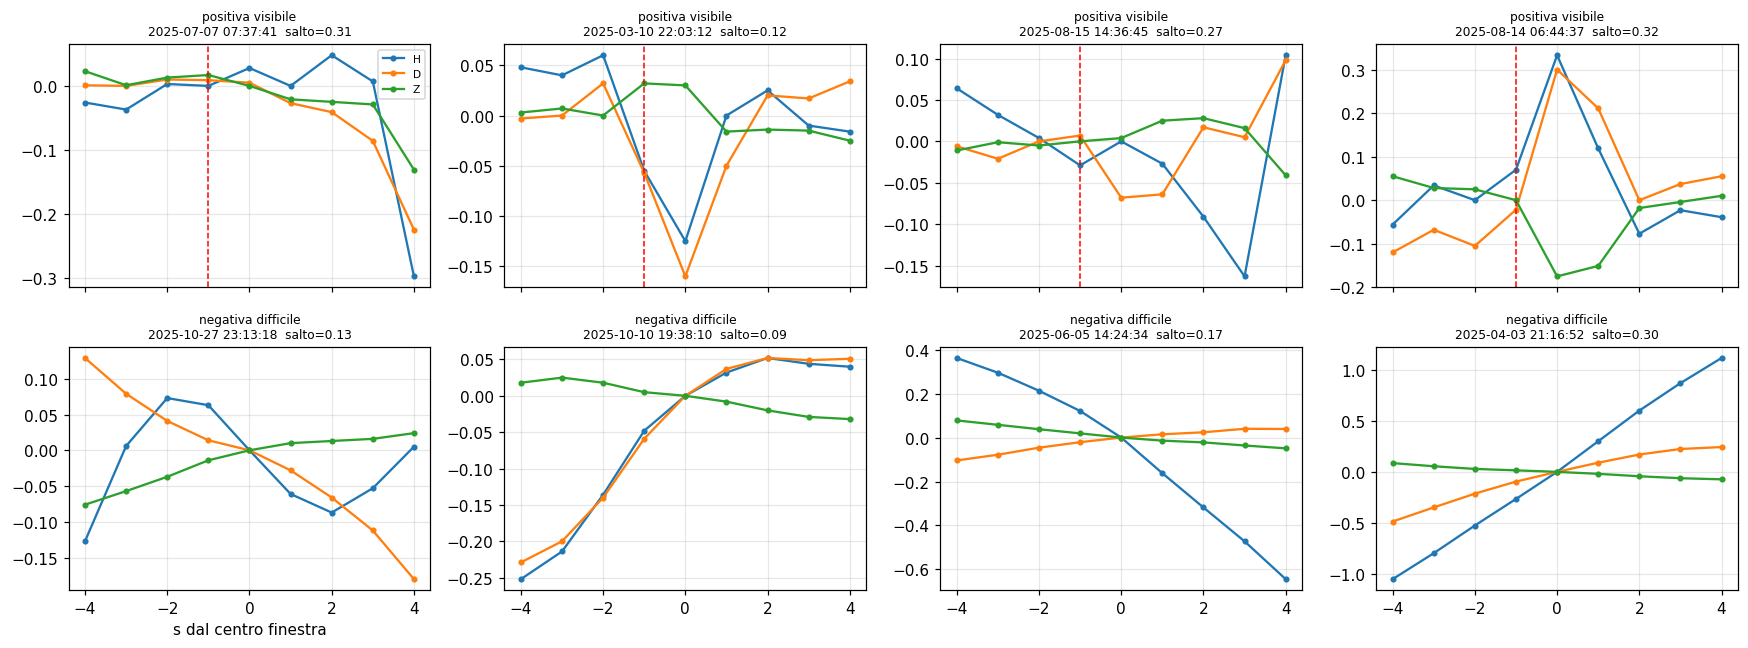

In [20]:
# Esempi: positive visibili vs negative difficili (stessa scala, baseline rimossa)
k = 4
ex_pos  = rng.choice(np.where(cat == 1)[0], min(k, (cat == 1).sum()), replace=False)
ex_hard = rng.choice(np.where((cat == 0) & (score >= SOGLIA_POS))[0],
                     min(k, ((cat == 0) & (score >= SOGLIA_POS)).sum()), replace=False)
comp_names = ["H", "D", "Z"]
t_axis = np.arange(-HALF_WINDOW, HALF_WINDOW + 1)
fig, axes = plt.subplots(2, k, figsize=(4 * k, 6), sharex=True)
for r, (gruppo, titolo) in enumerate([(ex_pos, "positiva visibile"), (ex_hard, "negativa difficile")]):
    for c_i, idx in enumerate(gruppo):
        ax = axes[r, c_i]
        w = dataset.windows[idx] - np.median(dataset.windows[idx], axis=0)
        for comp in range(3):
            ax.plot(t_axis, w[:, comp], "o-", ms=3, label=comp_names[comp])
        if r == 0:
            ax.axvline(-CENTER_OFFSET, color="red", ls="--", lw=1)
        ax.set_title(f"{titolo}\n{pd.Timestamp(dataset.t_center[idx])}  salto={md[idx]:.2f}", fontsize=8)
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7); axes[1, 0].set_xlabel("s dal centro finestra")
plt.tight_layout(); plt.show()

### Baseline senza rete
Classifica usando solo il criterio scelto (salto o SNR). La rete deve fare meglio di così.

In [21]:
from sklearn.metrics import average_precision_score, roc_auc_score
for nome, ii, cats in [("val", va_idx, [0, 1, 4]), ("test", te_idx, [0, 1, 4])]:
    m = np.isin(cat[ii], cats)
    y_b = (cat[ii][m] == 1).astype(int); s_b = score[ii][m]
    print(f"{nome:4s}: AUC-ROC={roc_auc_score(y_b, s_b):.4f}  AUC-PR={average_precision_score(y_b, s_b):.4f}"
          f"  (casuale = {y_b.mean():.5f})")

val : AUC-ROC=1.0000  AUC-PR=1.0000  (casuale = 0.00101)
test: AUC-ROC=0.9979  AUC-PR=0.2633  (casuale = 0.00008)


UC-ROC: la probabilità che, presa a caso una positiva e una negativa, la positiva abbia il punteggio (SNR) più alto. 1 = sempre, 0.5 = come tirare una moneta.

AUC-PR: misura quanto sono "pulite" le finestre con il punteggio più alto, cioè se in cima alla classifica ci sono soprattutto fulmini o anche molte negative. 1 = perfetto. Per eventi rari è la metrica più significativa.

"casuale": l'AUC-PR di un classificatore che tira a caso, pari alla frazione di positive. Nel test 116 positive su circa 1.5 milioni di finestre fanno 0.00008.

Sul validation la baseline ottiene AUC = 1 per costruzione: le positive visibili hanno SNR ≥ 5 per definizione e il validation contiene solo negative quiete (SNR < 3), quindi una soglia sull'SNR le separa perfettamente. Il risultato significativo è quello del test che include molte negative sicure con SNR elevato (disturbi lontani dai temporali): AUC-ROC = 0.998, ma AUC-PR = 0.26. L'AUC-ROC è dominata dall'enorme numero di negative facili, mentre l'AUC-PR mostra che tra le finestre con SNR più alto sono presenti molte negative difficili. È questo il valore di riferimento che la rete deve superare.

## 8 · Salvataggio del dataset per la rete neurale
Oltre a train / val / test vengono salvati, per il test, la categoria di ogni finestra (`g_test`), la distanza dal fulmine più vicino (`dt_test`), il salto (`score_test`) e se il giorno è senza fulmini (`dayfree_test`): servono alle tre misure di valutazione nel notebook della rete.

In [22]:
save_training_dataset(
    OUTPUT_FILE2,
    X_train=X_train, y_train=y_train, c_train=c_train, t_train=t_train,
    X_val=X_val,     y_val=y_val,     c_val=c_val,     t_val=t_val,
    X_test=X_test,   y_test=y_test,   c_test=c_test,   t_test=t_test,
    deriv_threshold=SOGLIA_POS,
    half_window=HALF_WINDOW,
    train_fraction=TRAIN_FRACTION,
    negative_ratio=NEG_RATIO,
    g_test=cat[te_idx],
    dt_test=dataset.dt_lightning[te_idx],
    score_test=score[te_idx],
    noise_train=dataset.noise_local[tr_idx],
    noise_val=dataset.noise_local[va_idx],
    noise_test=dataset.noise_local[te_idx],
    dayfree_test=~dataset.day_has_lightning[te_idx],
    negative_stride=NEGATIVE_STRIDE,
    center_offset=CENTER_OFFSET,
    criterio=CRITERIO,
)

Training dataset salvato in: C:\Programmi manuali\python\ProgrammiPython\CondaPyTorch\datasets\lightning_dataset50km_v2.npz
